# 01 — Faire mieux qu'une constante

**Question :** le contexte connu à l'avance (PDQ, mois, tendance) prédit-il mieux le nombre d'actes
de la semaine qu'une simple constante ?
On compare sur la **validation (2023)**, en changeant **une seule chose à la fois**.
Si un ajout n'aide pas, on garde le plus simple. Le **test reste fermé**.

**Contrat (v1, voir notebook 00) :** pour chaque PDQ actif, avant le début de la semaine,
estimer les actes déclarés de la semaine, à partir du calendrier seulement (PDQ, mois, temps écoulé).

In [1]:
import json
import hashlib
import tomllib
from pathlib import Path
import pandas as pd

ROOT = Path.cwd().parent
with open(ROOT / "configs/crimes.toml", "rb") as f:
    cfg = tomllib.load(f)

SEED = cfg["experiment"]["seed"]
DATA_PATH = ROOT / cfg["data"]["path"]
IN = ROOT / "artifacts" / "00_start_here"

panel = pd.read_parquet(IN / "panel.parquet")
meta = json.loads((IN / "meta.json").read_text())

# Provenance : le CSV a-t-il changé depuis la création du panel ?
empreinte = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()[:16]
print("Panel :", panel.shape, "| du", panel["SEMAINE"].min().date(), "au", panel["SEMAINE"].max().date())
print("Empreinte du CSV aujourd'hui :", empreinte, "| à la création du panel :", meta["source_sha16"])
assert empreinte == meta["source_sha16"], "Le CSV a changé depuis le notebook 00 : relance le 00 d'abord."

panel["ENSEMBLE"].value_counts()

Panel : (17835, 4) | du 2015-01-05 au 2026-10-12
Empreinte du CSV aujourd'hui : 8a28f8d8ad367780 | à la création du panel : 8a28f8d8ad367780


ENSEMBLE
train         12093
test           4234
validation     1508
Name: count, dtype: int64

## Variables connues à l'avance
`t` = années écoulées depuis la première semaine (la tendance) ; `mois` = 1 à 12 (la saison).
Les deux sont calculables avant le début de la semaine : elles respectent le contrat.

In [2]:
panel["t"] = (panel["SEMAINE"] - panel["SEMAINE"].min()).dt.days / 365.25
panel["t2"] = panel["t"] ** 2                 # ← nouvelle ligne : la tendance au carré
panel["mois"] = panel["SEMAINE"].dt.month

panel[["SEMAINE", "PDQ", "y", "t", "t2", "mois"]].head()

,SEMAINE,PDQ,y,t,t2,mois
0,2015-01-05,1,1,0.0,0.0,1
1,2015-01-05,3,7,0.0,0.0,1
2,2015-01-05,4,13,0.0,0.0,1
3,2015-01-05,5,14,0.0,0.0,1
4,2015-01-05,7,21,0.0,0.0,1


## Outil d'évaluation
Une seule fonction entraîne et note **tous** les modèles de la même façon : la comparaison est équitable.

In [3]:
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

train = panel[panel["ENSEMBLE"] == "train"]
validation = panel[panel["ENSEMBLE"] == "validation"]
# Pas de variable « test » : il reste fermé.

modeles = {}      # les modèles entraînés, par nom
resultats = []    # une ligne de notes par modèle

def evaluer(nom, estimateur, numeriques=(), categorielles=()):
    colonnes = list(numeriques) + list(categorielles)

    # 1. Préparation des colonnes
    etapes = []
    if numeriques:
        etapes.append(("num", StandardScaler(), list(numeriques)))
    if categorielles:
        etapes.append(("cat", OneHotEncoder(handle_unknown="ignore"), list(categorielles)))

    # 2. Préparation + modèle dans un seul pipeline, entraîné sur le TRAIN seulement
    modele = make_pipeline(ColumnTransformer(etapes), estimateur)
    modele.fit(train[colonnes], train["y"])

    # 3. Notes sur la validation (pour comparer) et sur le train (pour repérer le par-cœur)
    pred_validation = modele.predict(validation[colonnes])
    pred_train = modele.predict(train[colonnes])

    modeles[nom] = modele
    resultats.append({
        "modele": nom,
        "mae_validation": mean_absolute_error(validation["y"], pred_validation),
        "rmse_validation": root_mean_squared_error(validation["y"], pred_validation),
        "mae_train": mean_absolute_error(train["y"], pred_train),
    })
    return pd.DataFrame(resultats).set_index("modele").round(3)

## Référence : une constante
Avant tout vrai modèle : quelle erreur fait-on en prédisant la même valeur pour tous les PDQ et toutes les semaines ?

In [4]:
from sklearn.dummy import DummyRegressor

evaluer("moyenne", DummyRegressor(strategy="mean"), numeriques=["t"])
evaluer("mediane", DummyRegressor(strategy="median"), numeriques=["t"])

,mae_validation,rmse_validation,mae_train
modele,,,
moyenne,9.796,13.647,8.612
mediane,9.971,14.171,8.456


## La tendance seule
Une droite sur `t` (temps écoulé) fait-elle mieux que la constante ?

In [5]:
from sklearn.linear_model import LinearRegression

evaluer("tendance", LinearRegression(), numeriques=["t"])

,mae_validation,rmse_validation,mae_train
modele,,,
moyenne,9.796,13.647,8.612
mediane,9.971,14.171,8.456
tendance,9.948,14.106,8.584


**Constat — Tendance seule.** MAE 9,95 : moins bien que la constante (9,80).
La droite apprise sur 2015–2022 descend (6 années de baisse contre 2 de remontée) et prédit ~17 pour 2023, au lieu de ~22.

In [6]:
evaluer("pdq", LinearRegression(), categorielles=["PDQ"])

,mae_validation,rmse_validation,mae_train
modele,,,
moyenne,9.796,13.647,8.612
mediane,9.971,14.171,8.456
tendance,9.948,14.106,8.584
pdq,6.188,8.754,5.269


## Quand : ajouter le mois

In [7]:
evaluer("pdq_mois", LinearRegression(), categorielles=["PDQ", "mois"])

,mae_validation,rmse_validation,mae_train
modele,,,
moyenne,9.796,13.647,8.612
mediane,9.971,14.171,8.456
tendance,9.948,14.106,8.584
pdq,6.188,8.754,5.269
pdq_mois,6.159,8.664,5.158


## Ajouter la tendance au contexte

In [8]:
evaluer("pdq_mois_t", LinearRegression(), numeriques=["t"], categorielles=["PDQ", "mois"])

,mae_validation,rmse_validation,mae_train
modele,,,
moyenne,9.796,13.647,8.612
mediane,9.971,14.171,8.456
tendance,9.948,14.106,8.584
pdq,6.188,8.754,5.269
pdq_mois,6.159,8.664,5.158
pdq_mois_t,6.864,9.522,5.121


## Une tendance courbe : ajouter `t²`
Avec `t` et `t²`, une régression linéaire peut dessiner une parabole : elle peut suivre le « U » (baisse puis remontée).

In [9]:
evaluer("pdq_mois_t_t2", LinearRegression(), numeriques=["t", "t2"], categorielles=["PDQ", "mois"])

,mae_validation,rmse_validation,mae_train
modele,,,
moyenne,9.796,13.647,8.612
mediane,9.971,14.171,8.456
tendance,9.948,14.106,8.584
pdq,6.188,8.754,5.269
pdq_mois,6.159,8.664,5.158
pdq_mois_t,6.864,9.522,5.121
pdq_mois_t_t2,5.993,7.972,4.987


## Pourquoi `t²` change tout : les prédictions année par année

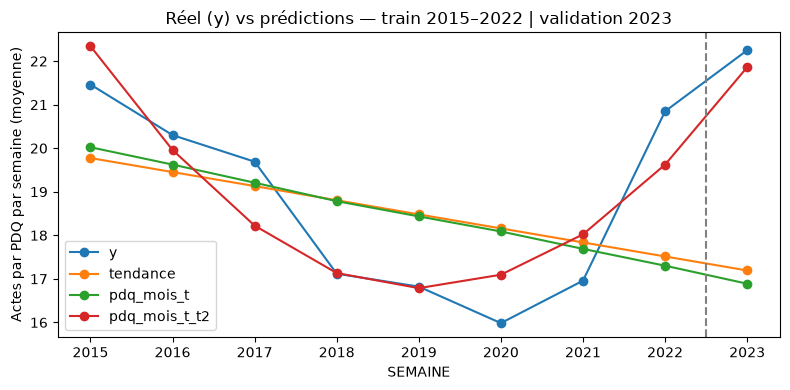

,y,tendance,pdq_mois_t,pdq_mois_t_t2
SEMAINE,,,,
2015,21.5,19.8,20.0,22.3
2016,20.3,19.5,19.6,20.0
2017,19.7,19.1,19.2,18.2
2018,17.1,18.8,18.8,17.1
2019,16.8,18.5,18.4,16.8
2020,16.0,18.2,18.1,17.1
2021,17.0,17.8,17.7,18.0
2022,20.8,17.5,17.3,19.6
2023,22.2,17.2,16.9,21.9


In [10]:
import matplotlib.pyplot as plt

connu = panel[panel["ENSEMBLE"].isin(["train", "validation"])].copy()   # jamais le test
for nom in ["tendance", "pdq_mois_t", "pdq_mois_t_t2"]:
    m = modeles[nom]
    connu[nom] = m.predict(connu[list(m.feature_names_in_)])   # chaque modèle reçoit SES colonnes

par_annee = connu.groupby(connu["SEMAINE"].dt.year)[["y", "tendance", "pdq_mois_t", "pdq_mois_t_t2"]].mean()

ax = par_annee.plot(marker="o", figsize=(8, 4))
ax.axvline(2022.5, color="grey", linestyle="--")          # frontière train | validation
ax.set_ylabel("Actes par PDQ par semaine (moyenne)")
ax.set_title("Réel (y) vs prédictions — train 2015–2022 | validation 2023")
plt.tight_layout()
plt.show()

par_annee.round(1)

## Régulariser les mêmes entrées : Ridge
Mêmes colonnes que `pdq_mois_t_t2` (PDQ, mois, t, t²), mais avec une pénalité sur la taille des poids.
On teste trois forces de pénalité : alpha = 100 (forte), 10 (moyenne), 1 (faible).
Question : la pénalité améliore-t-elle l'erreur sur la validation ?

In [11]:
from sklearn.linear_model import Ridge

for alpha in [100, 10, 1]:
    tableau = evaluer(f"ridge_{alpha}", Ridge(alpha=alpha),
                      numeriques=["t", "t2"], categorielles=["PDQ", "mois"])
tableau

,mae_validation,rmse_validation,mae_train
modele,,,
moyenne,9.796,13.647,8.612
mediane,9.971,14.171,8.456
tendance,9.948,14.106,8.584
pdq,6.188,8.754,5.269
pdq_mois,6.159,8.664,5.158
pdq_mois_t,6.864,9.522,5.121
pdq_mois_t_t2,5.993,7.972,4.987
ridge_100,6.306,8.630,5.168
ridge_10,6.014,8.030,4.991


In [12]:
coefs = pd.DataFrame({
    nom: pd.Series(modeles[nom][-1].coef_, index=modeles[nom][:-1].get_feature_names_out())
    for nom in ["pdq_mois_t_t2", "ridge_10", "ridge_100"]
})
coefs.loc[["num__t", "num__t2", "cat__PDQ_38", "cat__PDQ_50"]].round(2)

,pdq_mois_t_t2,ridge_10,ridge_100
num__t,-7.00,-6.83,-5.62
num__t2,6.31,6.14,4.94
cat__PDQ_38,22.49,21.96,18.14
cat__PDQ_50,-14.06,-13.73,-11.34


**Constat — Ridge.** Plus la pénalité est forte, plus les poids sont tirés vers 0
(PDQ 38 : +22,5 sans pénalité, +18,1 avec α=100) et plus l'erreur augmente
(α=100 : 6,31 ; α=10 : 6,01 ; α=1 : 5,995 ; sans pénalité : 5,993).
Avec 12 093 lignes pour 43 colonnes, le modèle linéaire ne surapprend pas : la pénalité retire de la vraie information.
On garde le modèle sans pénalité.

## Choix du modèle
Règle : le modèle retenu est celui qui a la plus petite MAE sur la validation (2023).
On mesure son gain par rapport à la référence (prédire la moyenne du train).

In [13]:
tableau = pd.DataFrame(resultats).set_index("modele")
choix = tableau["mae_validation"].idxmin()
reference = tableau.loc["moyenne", "mae_validation"]
gain = reference - tableau.loc[choix, "mae_validation"]

print("Modèle retenu :", choix)
print(f"MAE validation : {tableau.loc[choix, 'mae_validation']:.3f} (référence : {reference:.3f})")
print(f"Gain : {gain:.2f} actes par PDQ-semaine, soit {gain / reference:.0%} d'erreur en moins")

Modèle retenu : pdq_mois_t_t2
MAE validation : 5.993 (référence : 9.796)
Gain : 3.80 actes par PDQ-semaine, soit 39% d'erreur en moins


## Erreurs par PDQ (validation 2023)
erreur = réel − prédit. Positive : le modèle sous-estime. Négative : il surestime.
MAE = taille moyenne de l'erreur. Biais = moyenne de l'erreur avec son signe (erreur systématique).

In [14]:
m = modeles[choix]
val = validation.copy()
val["prediction"] = m.predict(val[list(m.feature_names_in_)])
val["erreur"] = val["y"] - val["prediction"]

par_pdq = val.groupby("PDQ").agg(
    moyenne_y=("y", "mean"),
    mae=("erreur", lambda e: e.abs().mean()),
    biais=("erreur", "mean"),
).sort_values("mae", ascending=False)

print("Biais global :", round(val["erreur"].mean(), 2))
par_pdq.round(2)

Biais global : 0.39


,moyenne_y,mae,biais
PDQ,,,
21,48.56,12.29,11.34
38,51.54,11.26,7.19
20,43.62,10.21,7.94
26,36.35,8.93,8.22
5,26.37,8.09,6.76
7,32.81,7.29,3.25
9,20.44,7.20,6.79
15,30.40,6.28,5.19
23,23.77,6.14,-2.05


**Constat — Erreurs par PDQ.** Le biais global est presque nul (0,39), mais il cache un motif :
les gros PDQ sont sous-estimés (PDQ 21 : +11,3 ; PDQ 20 : +7,9 ; PDQ 38 : +7,2 actes par semaine)
et les petits sont surestimés (PDQ 4 : −2,6 ; PDQ 1 : −2,4).
Le modèle est additif : la même tendance est ajoutée à tous les PDQ, alors que la remontée 2021–2023 a été plus forte dans les gros postes.

## Sauvegarde
Les résultats sont écrits dans `artifacts/01_regression_lineaire/`, avec l'empreinte des données et la preuve que le test n'a pas été regardé.

In [15]:
OUT = ROOT / "artifacts" / "01_regression_lineaire"
OUT.mkdir(parents=True, exist_ok=True)

tableau.round(3).to_csv(OUT / "resultats.csv")
coefs.round(3).to_csv(OUT / "coefficients.csv")
par_pdq.round(2).to_csv(OUT / "erreurs_par_pdq.csv")

meta_01 = {
    "source_sha16": meta["source_sha16"],
    "contrat": "v1 : PDQ x semaine, calendrier seulement (PDQ, mois, t), avant le debut de la semaine",
    "metrique": "mae",
    "choix_sur": "validation",
    "reference": "moyenne",
    "mae_reference": round(float(reference), 3),
    "modele_retenu": choix,
    "colonnes": list(modeles[choix].feature_names_in_),
    "mae_validation": round(float(tableau.loc[choix, "mae_validation"]), 3),
    "gain": round(float(gain), 3),
    "reduction_relative": round(float(gain / reference), 3),
    "biais_global": round(float(val["erreur"].mean()), 3),
    "test_regarde": False,
}
(OUT / "meta.json").write_text(json.dumps(meta_01, indent=2, ensure_ascii=False))
sorted(p.name for p in OUT.iterdir())

['coefficients.csv', 'erreurs_par_pdq.csv', 'meta.json', 'resultats.csv']

## Résumé

| Étape | Modèle | MAE validation |
|---|---|---|
| Référence | moyenne | 9,80 |
| Temps seul | tendance (t) | 9,95 |
| Où | PDQ | 6,19 |
| Où + quand | PDQ + mois | 6,16 |
| + droite | PDQ + mois + t | 6,86 |
| + courbe | **PDQ + mois + t + t²** | **5,99** |
| Pénalité | Ridge α = 1 / 10 / 100 | 6,00 / 6,01 / 6,31 |

**Ce qu'on retient.**
- Le modèle retenu (PDQ + mois + t + t²) se trompe en moyenne de **6,0 actes** par PDQ-semaine, contre 9,8 pour la constante : **39 % d'erreur en moins**.
- Le **PDQ** apporte l'essentiel du gain ; le mois est un petit effet ; la tendance n'aide que si elle peut **courber**.
- La régularisation n'apporte rien : on garde le modèle simple.

**Limites connues.**
- **Parabole :** `t²` monte sans fin. Le modèle prédit 24,8 en 2024, 28,4 en 2025 et 32,1 en 2026 : une extrapolation dangereuse, même si 2023 (juste à côté du train) est bien prédite.
- **Modèle additif :** la même tendance est ajoutée à tous les PDQ. Les gros postes sont sous-estimés (PDQ 21 : +11,3 actes par semaine) et les petits surestimés (PDQ 1 : −2,4), alors que le biais global (0,39) semble nul.
- **Fermeture du PDQ 22 (fin 2024) :** le territoire du PDQ 21 s'agrandit, mais le modèle ne le sait pas.
- **Choix provisoire :** il est fait sur la validation seulement ; le test reste fermé.

Suite : notebook 02, des arbres capables de capter des interactions PDQ × temps.